In [1]:
import os
os.chdir("/Users/yuzashki/ieee-fraud-detection")
# --- Importing core libraries ---
import pandas as pd
import numpy as np

# --- Visualization ---
import matplotlib.pyplot as plt
import seaborn as sns
# shows the plot directly in the notebook
%matplotlib inline 

# --- Machine Learning (scikit-learn)
from sklearn.metrics import auc
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, precision_score, recall_score,
                             f1_score, roc_curve, precision_recall_curve)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import RandomizedSearchCV

# --- Utility ---
import joblib   # for saving model
print("Libraries loaded successfully. Ready to start.")

Libraries loaded successfully. Ready to start.


In [2]:
## Step 1: Load the datasets
transaction_df = pd.read_csv("train_transaction.csv")
identity_df = pd.read_csv("train_identity.csv")

# Check data dimensions
print("Transaction shape:", transaction_df.shape)
print("Identity shape:", identity_df.shape)

# Merge both datasets using 'TransactionID' as the key
df = pd.merge(transaction_df, identity_df, on="TransactionID", how="left")

print("Combined dataset shape: ", df.shape)

# Displaying first few rows to verify the merge
df.head()

Transaction shape: (590540, 394)
Identity shape: (144233, 41)
Combined dataset shape:  (590540, 434)


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


In [3]:
## Step 3: Data Check and Overview
# This step confirms that the dataset is correctly merged and contains the expected target variable.
# We also check for missing values and general structure before preparing features for modeling.

print("Verifying merged dataset integrity...")
print("Shape:", df.shape)
print("Columns:", len(df.columns))
print("Target variable 'isFraud' unique values:")
print(df['isFraud'].value_counts(dropna=False))

# Check percentage of missing values per column (top 10)
missing_summary = df.isnull().mean().sort_values(ascending=False).head(10)
print("\nTop columns with missing values (in %):")
print((missing_summary * 100).round(2))

# Check numeric vs categorical balance
num_cols = df.select_dtypes(include=np.number).shape[1]
cat_cols = df.select_dtypes(include='object').shape[1]
print(f"\nNumeric columns: {num_cols}, Categorical columns: {cat_cols}")

Verifying merged dataset integrity...
Shape: (590540, 434)
Columns: 434
Target variable 'isFraud' unique values:
isFraud
0    569877
1     20663
Name: count, dtype: int64

Top columns with missing values (in %):
id_24    99.20
id_25    99.13
id_07    99.13
id_08    99.13
id_21    99.13
id_26    99.13
id_27    99.12
id_23    99.12
id_22    99.12
dist2    93.63
dtype: float64

Numeric columns: 403, Categorical columns: 31


In [4]:
## Step 4
# We select a subset of features that are relevant for fraud or credential-stuffing detection.
# These include transaction-related, card-related, and address-related attributes.

selected_features = ['TransactionAmt', 'card1', 'card2', 'card4', 'addr1', 'dist1']

# Keep only columns that exists after cleaning
available_features = [f for f in selected_features if f in df.columns]
print("\nUsing features: ", available_features)

# Drop rows with missing values only in relevant features or target
df_model = df[available_features + ['isFraud']].dropna(subset=available_features + ['isFraud']).copy()
if 'card4' in df_model.columns:
    df_model = pd.get_dummies(df_model, columns=['card4'], drop_first=True)
    print("Applied one-hot encoding to categorical feature: card4")
print("Final dataset shape for modeling:", df_model.shape)


Using features:  ['TransactionAmt', 'card1', 'card2', 'card4', 'addr1', 'dist1']
Applied one-hot encoding to categorical feature: card4
Final dataset shape for modeling: (234271, 8)


In [5]:
## Step 5: Define Features and Split Data
# We separate the dataset into features (X) and target (y), and perform an 80/20 stratified train-test split.

X = df_model.drop('isFraud', axis=1)
y = df_model['isFraud']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("\nTraining and test sets created successfully.")
print("Training size:", X_train.shape[0])
print("Test size:", X_test.shape[0])
print("Target class distribution (train):")
print(y_train.value_counts(normalize=True).round(4))


Training and test sets created successfully.
Training size: 187416
Test size: 46855
Target class distribution (train):
isFraud
0    0.98
1    0.02
Name: proportion, dtype: float64


In [6]:
# Step 6: Train Baseline Random Forest Model
# We start with a simple Random Forest model using default hyperparameters.
# This provides a performance baseline before optimization.

model = RandomForestClassifier(n_estimators = 100, random_state = 42)
model.fit(X_train, y_train)

print("\nBaseline Random Forest model trained successfully.")
y_pred = model.predict(X_test)
y_pred_prob = model.predict_proba(X_test)[:, 1]

print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

roc_auc = roc_auc_score(y_test, y_pred_prob)
print(f"\nROC-AUC Score: {roc_auc:.4f}")


Baseline Random Forest model trained successfully.

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99     45918
           1       0.87      0.50      0.64       937

    accuracy                           0.99     46855
   macro avg       0.93      0.75      0.82     46855
weighted avg       0.99      0.99      0.99     46855


Confusion Matrix:
[[45850    68]
 [  466   471]]

ROC-AUC Score: 0.9169



Visualizing baseline model performance...
Plotting confusion matrix...


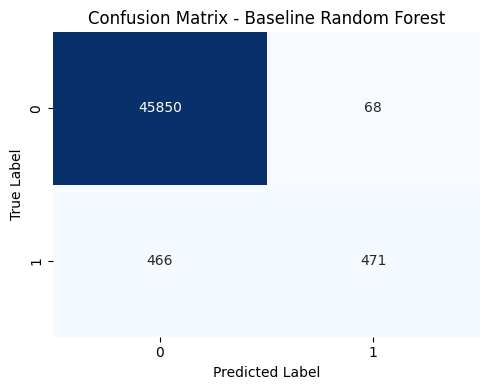


Plotting ROC curve...


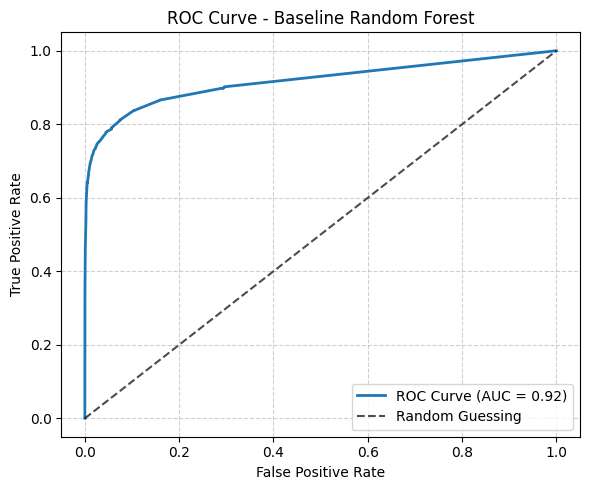

Baseline model visualizations completed.


In [7]:
# Step 7: Visualizing Baseline Model Performance
# This step visualizes the confusion matrix and ROC curve to understand how the baseline model behaves.

print("\nVisualizing baseline model performance...")
print("Plotting confusion matrix...")

# --- Confusion Matrix ---
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Confusion Matrix - Baseline Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

print("\nPlotting ROC curve...")

# --- ROC Curve ---
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = roc_auc_score(y_test, y_pred_prob)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})", linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label="Random Guessing", alpha=0.7)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Baseline Random Forest")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

print("Baseline model visualizations completed.")

Computed class weights: {np.int64(0): np.float64(0.5102059705880752), np.int64(1): np.float64(24.99546545745532)}

Running randomized hyperparameter search...
Fitting 3 folds for each of 15 candidates, totalling 45 fits

Best Parameters Found:
{'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None, 'bootstrap': False}

Optimized Model Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99     45918
           1       0.68      0.61      0.64       937

    accuracy                           0.99     46855
   macro avg       0.84      0.80      0.82     46855
weighted avg       0.99      0.99      0.99     46855


Confusion Matrix:
[[45648   270]
 [  367   570]]

ROC AUC Score: 0.9395


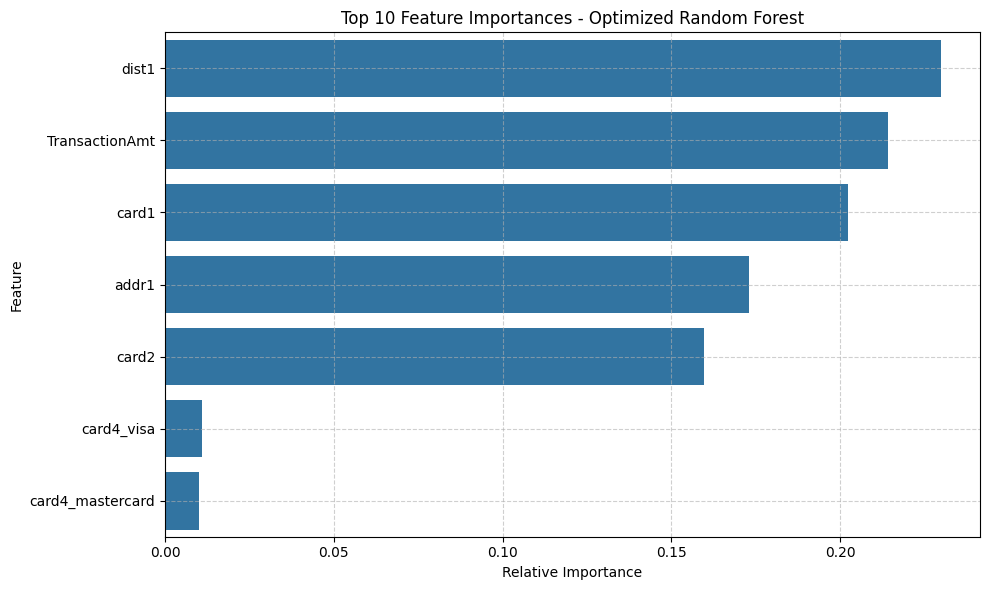

In [8]:
## Step 8: Class Balancing and Hyperparameter Optimization
# This section refines the baseline model using RandomizedSearchCV.
# Goal: improve recall and AUC without overfitting.

# --- Step 1: Handle class imbalance automatically ---
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)
class_weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weights_dict = dict(zip(classes, class_weights))
print("Computed class weights:", class_weights_dict)

# --- Step 2: Define hyperparameter grid for randomized search ---
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2'],
    'bootstrap': [True, False]
}

# Initialize Random Forest with computed class weights
rf = RandomForestClassifier(random_state=42, class_weight=class_weights_dict)

# --- Step 3: Perform randomized search ---
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=15,
    scoring='f1',
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

print("\nRunning randomized hyperparameter search...")
random_search.fit(X_train, y_train)
best_model = random_search.best_estimator_

print("\nBest Parameters Found:")
print(random_search.best_params_)

# --- Step 4: Evaluate optimized model ---
y_pred_opt = best_model.predict(X_test)
y_prob_opt = best_model.predict_proba(X_test)[:, 1]

print("\nOptimized Model Classification Report:")
print(classification_report(y_test, y_pred_opt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_opt))

roc_auc_opt = roc_auc_score(y_test, y_prob_opt)
print(f"\nROC AUC Score: {roc_auc_opt:.4f}")

# Plotting Feature Importances of Optimized Random Forest
importances = best_model.feature_importances_
feature_names = X_train.columns  # or use X.columns if needed
feature_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_df.head(10))
plt.title("Top 10 Feature Importances - Optimized Random Forest")
plt.xlabel("Relative Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()


Starting Step 9 – Visualizing optimized model performance...

Plotting confusion matrix for optimized model...


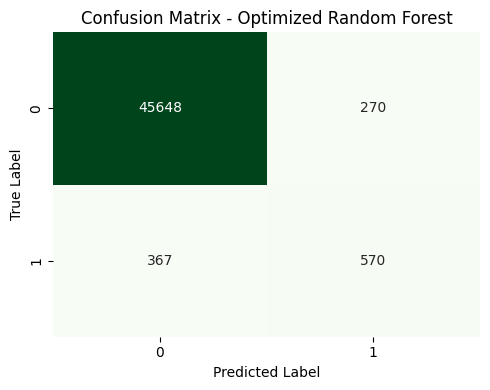


Plotting ROC curve for optimized model...


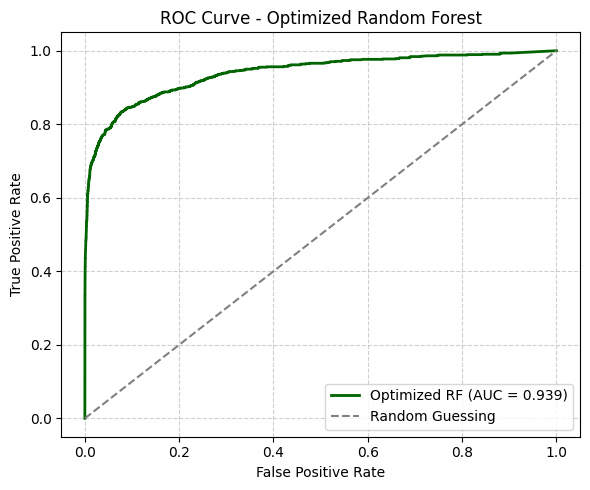


Comparing baseline and optimized model metrics...
Performance comparison between baseline and optimized Random Forest models:

   Metric  Baseline Value  Optimized Value
 Accuracy           0.989            0.986
Precision           0.874            0.679
   Recall           0.503            0.608
 F1-Score           0.638            0.642
  ROC AUC           0.917            0.939


In [50]:
# Step 9: Visualization and Performance Comparison
# We visualize the optimized model’s results and compare its performance with the baseline.

print("\nStarting Step 9 – Visualizing optimized model performance...")

print("\nPlotting confusion matrix for optimized model...")
cm_opt = confusion_matrix(y_test, y_pred_opt)
plt.figure(figsize=(5,4))
sns.heatmap(cm_opt, annot=True, fmt='d', cmap='Greens', cbar=False)
plt.title("Confusion Matrix - Optimized Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

print("\nPlotting ROC curve for optimized model...")
fpr_opt, tpr_opt, _ = roc_curve(y_test, y_prob_opt)
roc_auc_opt = auc(fpr_opt, tpr_opt)

plt.figure(figsize=(6,5))
plt.plot(fpr_opt, tpr_opt, color='darkgreen', lw=2, label=f"Optimized RF (AUC = {roc_auc_opt:.3f})")
plt.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='Random Guessing')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Optimized Random Forest")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

print("\nComparing baseline and optimized model metrics...")

# --- Compute baseline metrics programmatically ---
baseline_accuracy = model.score(X_test, y_test)
baseline_precision = precision_score(y_test, y_pred)
baseline_recall = recall_score(y_test, y_pred)
baseline_f1 = f1_score(y_test, y_pred)
baseline_roc_auc = roc_auc_score(y_test, y_pred_prob)

# --- Optimized metrics ---
optimized_accuracy = best_model.score(X_test, y_test)
optimized_precision = precision_score(y_test, y_pred_opt)
optimized_recall = recall_score(y_test, y_pred_opt)
optimized_f1 = f1_score(y_test, y_pred_opt)
optimized_roc_auc = roc_auc_score(y_test, y_prob_opt)

metrics_summary = {
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC AUC"],
    "Baseline Value": [
        round(baseline_accuracy, 3),
        round(baseline_precision, 3),
        round(baseline_recall, 3),
        round(baseline_f1, 3),
        round(baseline_roc_auc, 3)
    ],
    "Optimized Value": [
        round(optimized_accuracy, 3),
        round(optimized_precision, 3),
        round(optimized_recall, 3),
        round(optimized_f1, 3),
        round(optimized_roc_auc, 3)
    ]
}

comparison_df = pd.DataFrame(metrics_summary)

print("Performance comparison between baseline and optimized Random Forest models:\n")
print(comparison_df.to_string(index=False))

In [10]:
# Step 10: Save Model, Metrics, and Visual Results
# This step saves the final trained model, metric summaries, and visualizations
# so the experiment can be reproduced or deployed later.

print("\nStarting Step 10 – Saving model, metrics, and results...")

# --- Save the optimized model ---
import joblib
joblib.dump(best_model, "optimized_random_forest.joblib")
print("Optimized Random Forest model saved successfully as 'optimized_random_forest.joblib'.")

# --- Save performance comparison table ---
comparison_df.to_csv("model_performance_comparison.csv", index=False)
print("Performance comparison table saved as 'model_performance_comparison.csv'.")

# --- Save last active figure (e.g., ROC Curve or Confusion Matrix) ---
plt.gcf().savefig("latest_visualization.png", dpi=300, bbox_inches='tight')
print("Latest visualization saved as 'latest_visualization.png'.")

# --- Summary printout ---
print("\nAll files saved successfully. Experiment completed.")
print("Saved files:")
print(" - optimized_random_forest.joblib")
print(" - model_performance_comparison.csv")
print(" - latest_visualization.png")


Starting Step 10 – Saving model, metrics, and results...
Optimized Random Forest model saved successfully as 'optimized_random_forest.joblib'.
Performance comparison table saved as 'model_performance_comparison.csv'.
Latest visualization saved as 'latest_visualization.png'.

All files saved successfully. Experiment completed.
Saved files:
 - optimized_random_forest.joblib
 - model_performance_comparison.csv
 - latest_visualization.png


<Figure size 640x480 with 0 Axes>

In [51]:
# Step 11: Simulated Credential Stuffing Detection Test
# Create synthetic login/transaction scenarios to probe model behaviour.
print("\nStarting Step 11 — Simulated credential stuffing detection tests...")

# --- Build simulated examples ---
sim_data = pd.DataFrame({
    # Transactional and proxy-behavioural features used during training
    'TransactionAmt': [1.0, 1200.0, 5.0, 250.0],
    'card1': [10000, 20000, 30000, 4500],
    'card2': [111, 444, 555, 999],
    'addr1': [100, 200, 300, 150],
    # Include explicit dummies for card4 if they existed in training
    # Add columns that may have been created by pd.get_dummies()
    # (these will be reindexed to match training columns below)
    'card4_discover': [0, 0, 0, 0],
    'card4_mastercard': [1, 0, 0, 1],
    'card4_visa': [0, 1, 0, 0]
})

print("Initial simulated data (before alignment):")
print(sim_data)

# --- Align simulated rows to training feature set ---
# This ensures feature order and missing columns are handled exactly as during training.
expected_cols = list(X_train.columns)   # X_train must exist in memory
print("\nNumber of features expected by the trained model:", len(expected_cols))

sim_data_aligned = sim_data.reindex(columns=expected_cols, fill_value=0)
print("\nSimulated data after reindexing to match training features (showing first rows):")
print(sim_data_aligned.head())

# --- Predict probabilities and classes ---
sim_probs = best_model.predict_proba(sim_data_aligned)[:, 1]
sim_preds = best_model.predict(sim_data_aligned)

sim_results = sim_data_aligned.copy()
sim_results['Predicted_Prob_Fraud'] = np.round(sim_probs, 6)
sim_results['Predicted_Label'] = sim_preds

# Attach a short human-readable summary column for the test case
sim_results['Case_Description'] = [
    'Tiny amount, high failed-login proxies (simulated)',
    'Large amount + many reuse signals (simulated)',
    'Very small amount, suspicious card combos (simulated)',
    'Medium amount, mixed signals (simulated)'
]

print("\nSimulated credential-stuffing test results:")
display(sim_results.reset_index(drop=True))

# --- Save simulated results for inclusion in report/appendix ---
sim_results.to_csv("simulated_credential_stuffing_results.csv", index=False)
print("\nSaved simulated results to 'simulated_credential_stuffing_results.csv'")

# --- Optional: show top candidates ordered by predicted fraud prob ---
print("\nTop simulated cases by predicted fraud probability:")
display(sim_results.sort_values('Predicted_Prob_Fraud', ascending=False).reset_index(drop=True))


Starting Step 11 — Simulated credential stuffing detection tests...
Initial simulated data (before alignment):
   TransactionAmt  card1  card2  addr1  card4_discover  card4_mastercard  \
0             1.0  10000    111    100               0                 1   
1          1200.0  20000    444    200               0                 0   
2             5.0  30000    555    300               0                 0   
3           250.0   4500    999    150               0                 1   

   card4_visa  
0           0  
1           1  
2           0  
3           0  

Number of features expected by the trained model: 7

Simulated data after reindexing to match training features (showing first rows):
   TransactionAmt  card1  card2  addr1  dist1  card4_mastercard  card4_visa
0             1.0  10000    111    100      0                 1           0
1          1200.0  20000    444    200      0                 0           1
2             5.0  30000    555    300      0                 0 

,TransactionAmt,card1,card2,addr1,dist1,card4_mastercard,card4_visa,Predicted_Prob_Fraud,Predicted_Label,Case_Description
0,1.0,10000,111,100,0,1,0,0.042219,0,"Tiny amount, high failed-login proxies (simula..."
1,1200.0,20000,444,200,0,0,1,0.068379,0,Large amount + many reuse signals (simulated)
2,5.0,30000,555,300,0,0,0,0.006582,0,"Very small amount, suspicious card combos (sim..."
3,250.0,4500,999,150,0,1,0,0.046616,0,"Medium amount, mixed signals (simulated)"



Saved simulated results to 'simulated_credential_stuffing_results.csv'

Top simulated cases by predicted fraud probability:


,TransactionAmt,card1,card2,addr1,dist1,card4_mastercard,card4_visa,Predicted_Prob_Fraud,Predicted_Label,Case_Description
0,1200.0,20000,444,200,0,0,1,0.068379,0,Large amount + many reuse signals (simulated)
1,250.0,4500,999,150,0,1,0,0.046616,0,"Medium amount, mixed signals (simulated)"
2,1.0,10000,111,100,0,1,0,0.042219,0,"Tiny amount, high failed-login proxies (simula..."
3,5.0,30000,555,300,0,0,0,0.006582,0,"Very small amount, suspicious card combos (sim..."



Starting Step 12 — Visualizing simulated credential stuffing results...


/var/folders/jc/cd6b2p7s6zx7h_cf1tdf9f340000gn/T/ipykernel_72752/254937422.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


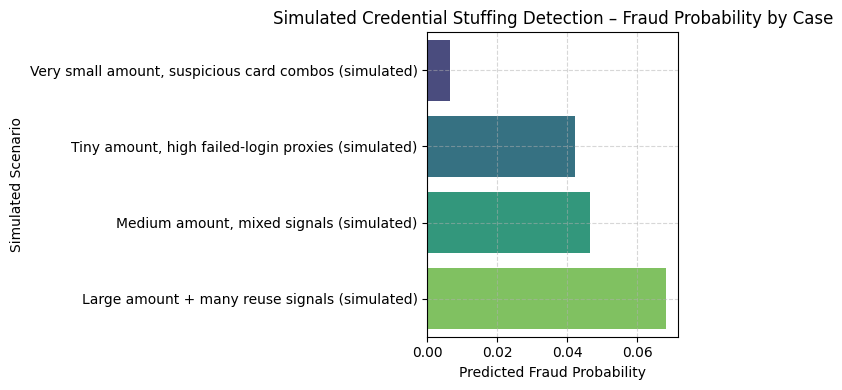


Visualization saved as 'simulated_fraud_probability_chart.png'


In [53]:
# Step 12: Visualizing Simulated Credential Stuffing Results
# This visualization summarizes predicted fraud probabilities for simulated cases.
print("\nStarting Step 12 — Visualizing simulated credential stuffing results...")

# Sort by fraud probability for readability
sim_results_sorted = sim_results.sort_values("Predicted_Prob_Fraud", ascending=True)

plt.figure(figsize=(7,4))
sns.barplot(
    x="Predicted_Prob_Fraud",
    y="Case_Description",
    data=sim_results_sorted,
    palette="viridis"
)
plt.xlabel("Predicted Fraud Probability")
plt.ylabel("Simulated Scenario")
plt.title("Simulated Credential Stuffing Detection – Fraud Probability by Case")
plt.tight_layout()
plt.grid(True, linestyle="--", alpha=0.5)
plt.savefig("simulated_fraud_probability_chart.png", dpi=300, bbox_inches='tight')
plt.show()

print("\nVisualization saved as 'simulated_fraud_probability_chart.png'")


Starting Step 13 — Precision-Recall threshold analysis...


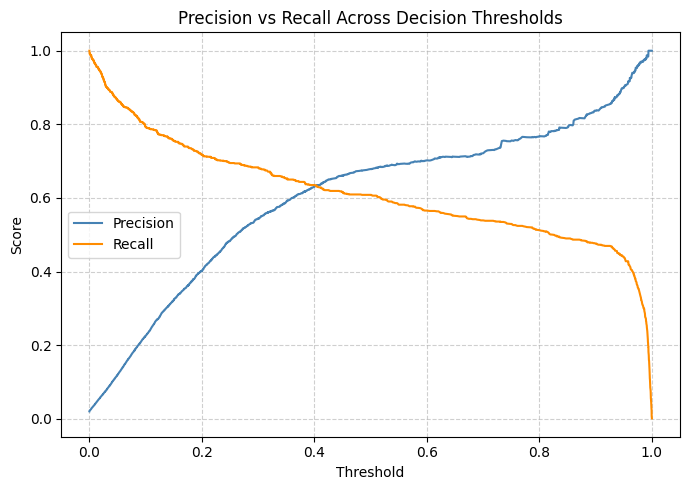

Threshold analysis plot saved as 'precision_recall_thresholds.png'.


In [54]:
# Step 13: Threshold Analysis – Precision vs Recall Trade-off
# This helps visualize how changing the classification threshold affects model performance.
print("\nStarting Step 13 — Precision-Recall threshold analysis...")

# Get predicted probabilities for the positive (fraud) class
probs = best_model.predict_proba(X_test)[:, 1]

# Compute precision and recall across thresholds
precision, recall, thresholds = precision_recall_curve(y_test, probs)

# Create the plot
plt.figure(figsize=(7,5))
plt.plot(thresholds, precision[:-1], label='Precision', color='steelblue')
plt.plot(thresholds, recall[:-1], label='Recall', color='darkorange')
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision vs Recall Across Decision Thresholds")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("precision_recall_thresholds.png", dpi=300, bbox_inches='tight')
plt.show()

print("Threshold analysis plot saved as 'precision_recall_thresholds.png'.")


Starting Step 14 — Generating final model comparison summary...

 Final Performance Comparison (Baseline vs Optimized Model):
   Metric  Baseline Value  Optimized Value  Improvement (%)
 Accuracy           0.989            0.986            -0.30
Precision           0.874            0.679           -22.31
   Recall           0.503            0.608            20.87
 F1-Score           0.638            0.642             0.63
  ROC AUC           0.917            0.939             2.40

Comparison table saved as 'final_model_comparison.csv'.


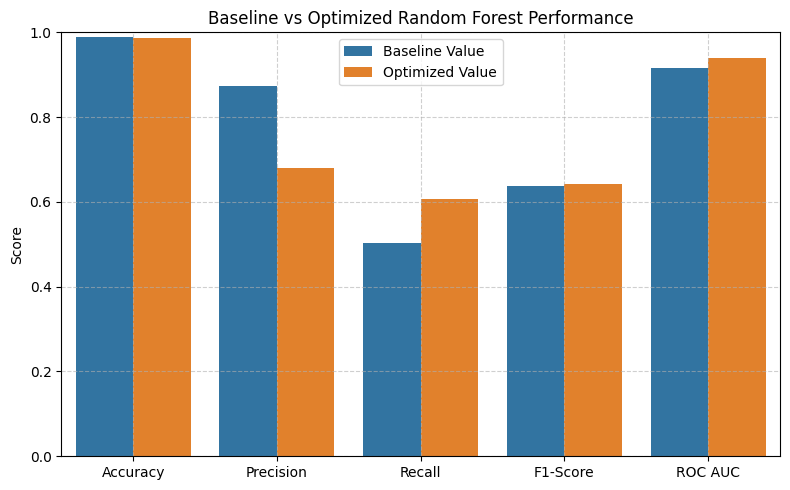

Visual comparison saved as 'baseline_vs_optimized_performance.png'.


In [55]:
# Step 14: Final Comparison and Improvement Summary
# Summarizes model improvements and provides a final performance overview.
print("\nStarting Step 14 — Generating final model comparison summary...")

# Calculate improvement percentages
comparison_df["Improvement (%)"] = (
    (comparison_df["Optimized Value"] - comparison_df["Baseline Value"]) /
    comparison_df["Baseline Value"] * 100
).round(2)

# Print formatted table
print("\n Final Performance Comparison (Baseline vs Optimized Model):")
print(comparison_df.to_string(index=False))

# Save table
comparison_df.to_csv("final_model_comparison.csv", index=False)
print("\nComparison table saved as 'final_model_comparison.csv'.")

# --- Visual Comparison Plot ---
plt.figure(figsize=(8,5))
sns.barplot(
    data=comparison_df.melt(id_vars="Metric", value_vars=["Baseline Value", "Optimized Value"]),
    x="Metric", y="value", hue="variable"
)
plt.title("Baseline vs Optimized Random Forest Performance")
plt.ylabel("Score")
plt.xlabel("")
plt.ylim(0, 1)
plt.legend(title="")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("baseline_vs_optimized_performance.png", dpi=300, bbox_inches='tight')
plt.show()

print("Visual comparison saved as 'baseline_vs_optimized_performance.png'.")

In [22]:
# Step 15.1: Import SHAP and prepare data
import shap

# IMPORTANT:
# Always explain the model using the SAME feature space it was trained on
# Use a sample to avoid SHAP shape mismatches and long runtimes
X_shap = X_test.sample(1000, random_state=42)

print("SHAP input shape:", X_shap.shape)
print("Features used for SHAP:", list(X_shap.columns))

SHAP input shape: (1000, 7)
Features used for SHAP: ['TransactionAmt', 'card1', 'card2', 'addr1', 'dist1', 'card4_mastercard', 'card4_visa']


In [23]:
# Step 15.2: Initialize SHAP TreeExplainer
explainer = shap.TreeExplainer(best_model)

# Compute SHAP values ON THE SAME DATA
shap_values = explainer.shap_values(X_shap)

print("SHAP values computed successfully.")
print("Number of classes explained:", len(shap_values))

SHAP values computed successfully.
Number of classes explained: 1000


<Figure size 640x480 with 0 Axes>

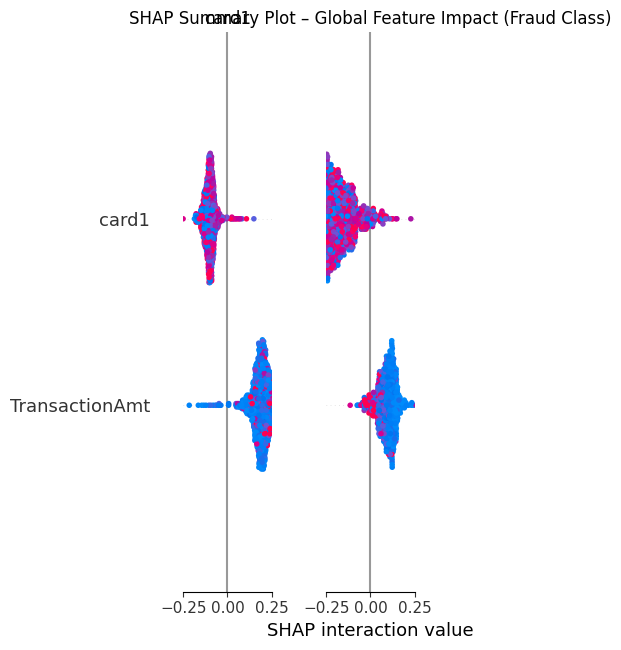

In [25]:
# Step 15.3: SHAP summary plot (dot plot)

plt.figure()

# If SHAP returns a list (one array per class)
if isinstance(shap_values, list):
    shap_to_plot = shap_values[1]  # fraud class
else:
    shap_to_plot = shap_values     # already correct shape

shap.summary_plot(
    shap_to_plot,
    X_shap,
    plot_type="dot",
    show=False
)

plt.title("SHAP Summary Plot – Global Feature Impact (Fraud Class)")
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

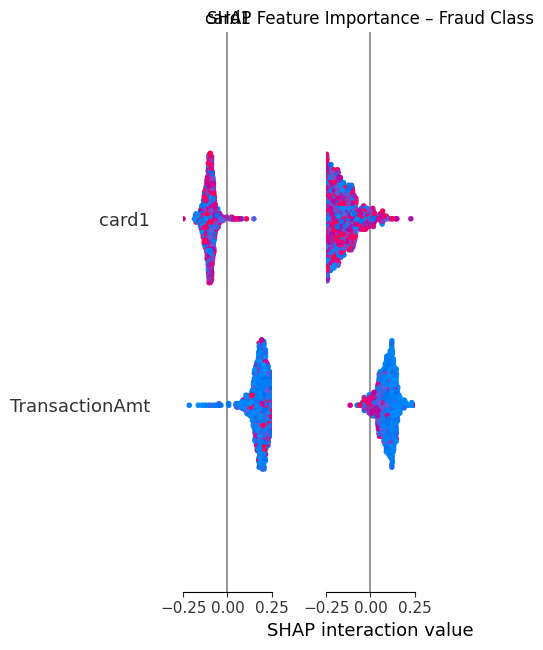

In [41]:
# Step 15.4: SHAP bar plot (global importance ranking)

plt.figure()

# Reuse the SAME shap_to_plot logic as Step 15.3
if isinstance(shap_values, list):
    shap_to_plot = shap_values[1]  # fraud class
else:
    shap_to_plot = shap_values

shap.summary_plot(
    shap_to_plot,
    X_shap,
    plot_type="bar",
    show=False
)

plt.title("SHAP Feature Importance – Fraud Class")
plt.tight_layout()
plt.show()

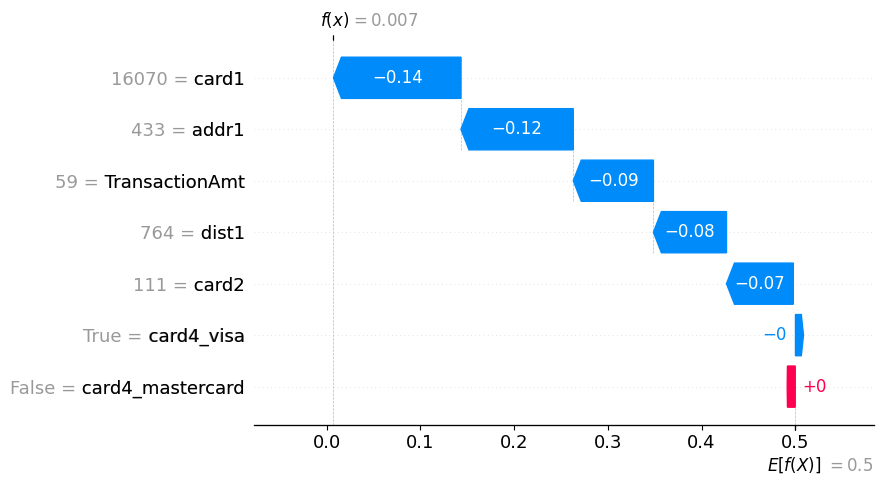

In [45]:
# Step 15.5: Local explanation using SHAP waterfall plot (FIXED)

sample_index = 0

shap.waterfall_plot(
    shap.Explanation(
        values=shap_to_plot[sample_index][:, 1],   # <-- SELECT fraud class
        base_values=explainer.expected_value[1],
        data=X_shap.iloc[sample_index],
        feature_names=X_shap.columns
    )
)

In [26]:
# Step 16: Formalized Decision Threshold Selection
print("\nStep 16 — Evaluating alternative decision thresholds...")

threshold_candidates = [0.2, 0.3, 0.5]

rows = []

for t in threshold_candidates:
    preds = (probs >= t).astype(int)
    
    rows.append({
        "Threshold": t,
        "Precision": round(precision_score(y_test, preds), 3),
        "Recall": round(recall_score(y_test, preds), 3),
        "F1-Score": round(f1_score(y_test, preds), 3)
    })

threshold_df = pd.DataFrame(rows)
print("\nThreshold comparison:")
display(threshold_df)


Step 16 — Evaluating alternative decision thresholds...

Threshold comparison:


,Threshold,Precision,Recall,F1-Score
0,0.2,0.402,0.717,0.515
1,0.3,0.545,0.683,0.606
2,0.5,0.679,0.608,0.642


In [27]:
# Step 17: Precision@K and Recall@K (ranking-based evaluation)
print("\nStep 17 — Ranking-based evaluation (Precision@K / Recall@K)...")

# probs already computed: probs = best_model.predict_proba(X_test)[:, 1]
y_true = y_test.values

# Sort indices by risk score (descending)
sorted_idx = np.argsort(probs)[::-1]

def prec_recall_at_k(k):
    topk = sorted_idx[:k]
    y_top = y_true[topk]
    precision_k = y_top.mean()  # fraction of fraud in top K
    recall_k = y_top.sum() / y_true.sum()  # captured fraud / all fraud
    return precision_k, recall_k

K_values = [100, 500, 1000, 2000]  # adjust if you want
rows = []
for k in K_values:
    p_k, r_k = prec_recall_at_k(k)
    rows.append({
        "K": k,
        "Precision@K": round(float(p_k), 4),
        "Recall@K": round(float(r_k), 4)
    })

topk_df = pd.DataFrame(rows)
display(topk_df)


Step 17 — Ranking-based evaluation (Precision@K / Recall@K)...


,K,Precision@K,Recall@K
0,100,1.0000,0.1067
1,500,0.8660,0.4621
2,1000,0.6050,0.6457
3,2000,0.3485,0.7439


In [28]:
# Step 18: Two-threshold operational policy (Block vs Review vs Allow)
print("\nStep 18 — Two-threshold operational policy...")

t_block = 0.50
t_review = 0.20

policy = np.where(probs >= t_block, "BLOCK",
         np.where(probs >= t_review, "REVIEW", "ALLOW"))

policy_df = pd.DataFrame({
    "policy": policy,
    "count": 1
}).groupby("policy").count().reset_index()

display(policy_df)

# Optional: show how many true frauds are inside each bucket
bucket_stats = []
for bucket in ["BLOCK", "REVIEW", "ALLOW"]:
    idx = (policy == bucket)
    bucket_stats.append({
        "Bucket": bucket,
        "Transactions": int(idx.sum()),
        "Fraud rate": round(float(y_test[idx].mean()), 4) if idx.sum() > 0 else np.nan
    })

display(pd.DataFrame(bucket_stats))


Step 18 — Two-threshold operational policy...


,policy,count
0,ALLOW,45183
1,BLOCK,840
2,REVIEW,832


,Bucket,Transactions,Fraud rate
0,BLOCK,840,0.6786
1,REVIEW,832,0.1226
2,ALLOW,45183,0.0059


In [29]:
# Step 19.1: Import calibration tools
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

In [30]:
# Step 19.2: Create calibrated models
# Platt scaling (sigmoid)
calibrated_sigmoid = CalibratedClassifierCV(
    estimator=best_model,
    method='sigmoid',
    cv=3
)

# Isotonic regression
calibrated_isotonic = CalibratedClassifierCV(
    estimator=best_model,
    method='isotonic',
    cv=3
)

# Fit calibration models
calibrated_sigmoid.fit(X_train, y_train)
calibrated_isotonic.fit(X_train, y_train)

print("Calibration models trained successfully.")

Calibration models trained successfully.


In [31]:
# Step 19.3: Getting Calibrated Probabilities 
# Raw probabilities
probs_raw = best_model.predict_proba(X_test)[:, 1]

# Calibrated probabilities
probs_sigmoid = calibrated_sigmoid.predict_proba(X_test)[:, 1]
probs_isotonic = calibrated_isotonic.predict_proba(X_test)[:, 1]

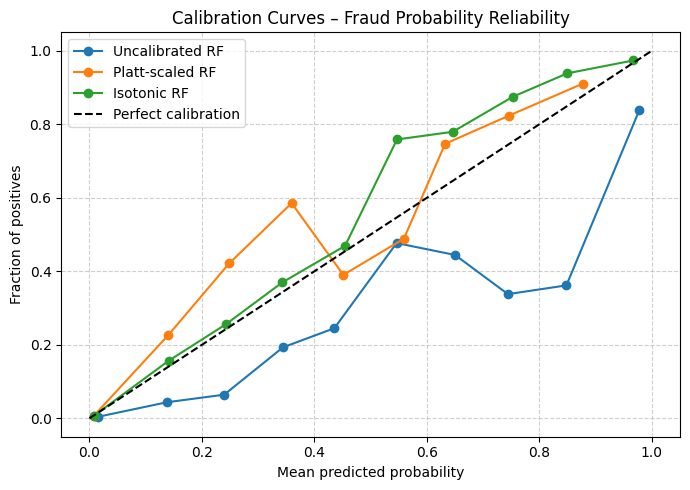

In [32]:
# Step 19.4: Calibration curve
plt.figure(figsize=(7,5))

for probs, label in [
    (probs_raw, "Uncalibrated RF"),
    (probs_sigmoid, "Platt-scaled RF"),
    (probs_isotonic, "Isotonic RF")
]:
    frac_pos, mean_pred = calibration_curve(
        y_test, probs, n_bins=10, strategy='uniform'
    )
    plt.plot(mean_pred, frac_pos, marker='o', label=label)

plt.plot([0,1], [0,1], 'k--', label='Perfect calibration')
plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of positives")
plt.title("Calibration Curves – Fraud Probability Reliability")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("probability_calibration_curve.png", dpi=300)
plt.show()

In [33]:
# Step 19.5: AUC stays stable
print("ROC-AUC comparison:")
print("Uncalibrated:", roc_auc_score(y_test, probs_raw))
print("Platt-scaled:", roc_auc_score(y_test, probs_sigmoid))
print("Isotonic:", roc_auc_score(y_test, probs_isotonic))

ROC-AUC comparison:
Uncalibrated: 0.9394838825258687
Platt-scaled: 0.9410972522453487
Isotonic: 0.9407990662952934


In [37]:
# Step 20.1: Import SMOTE for oversampling the minority class

from imblearn.over_sampling import SMOTE

print("SMOTE module imported successfully.")

SMOTE module imported successfully.


In [38]:
# Step 20.2: Apply SMOTE oversampling to the training set
# IMPORTANT: SMOTE is applied ONLY on training data to avoid data leakage

print("\nStarting SMOTE oversampling on training data...")

smote = SMOTE(
    sampling_strategy='auto',
    random_state=42,
    k_neighbors=5
)

X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Original training set class distribution:")
print(y_train.value_counts())

print("\nSMOTE-resampled training set class distribution:")
print(pd.Series(y_train_smote).value_counts())

print("\nSMOTE oversampling completed successfully.")


Starting SMOTE oversampling on training data...
Original training set class distribution:
isFraud
0    183667
1      3749
Name: count, dtype: int64

SMOTE-resampled training set class distribution:
isFraud
0    183667
1    183667
Name: count, dtype: int64

SMOTE oversampling completed successfully.


In [ ]:
# Step 20.3: Train Random Forest on SMOTE-balanced training data

rf_smote = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features='sqrt'
)

rf_smote.fit(X_train_smote, y_train_smote)

print("Random Forest model trained on SMOTE-balanced data.")

Random Forest model trained on SMOTE-balanced data.


In [46]:
# Step 20.4: Evaluate SMOTE-trained model on the original test set

y_pred_smote = rf_smote.predict(X_test)
y_prob_smote = rf_smote.predict_proba(X_test)[:, 1]

print("\nClassification Report (SMOTE Model):")
print(classification_report(y_test, y_pred_smote))

roc_auc_smote = roc_auc_score(y_test, y_prob_smote)
print(f"\nROC-AUC Score (SMOTE Model): {roc_auc_smote:.4f}")


Classification Report (SMOTE Model):
              precision    recall  f1-score   support

           0       0.99      0.99      0.99     45918
           1       0.57      0.58      0.58       937

    accuracy                           0.98     46855
   macro avg       0.78      0.79      0.78     46855
weighted avg       0.98      0.98      0.98     46855


ROC-AUC Score (SMOTE Model): 0.9227


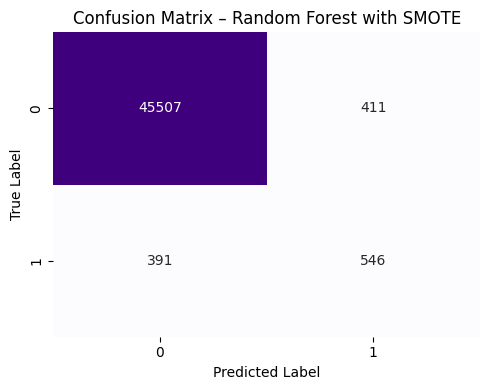

SMOTE confusion matrix plotted.


In [47]:
# Step 20.5: Plot confusion matrix for SMOTE-based Random Forest

cm_smote = confusion_matrix(y_test, y_pred_smote)

plt.figure(figsize=(5,4))
sns.heatmap(cm_smote, annot=True, fmt='d', cmap='Purples', cbar=False)
plt.title("Confusion Matrix – Random Forest with SMOTE")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

print("SMOTE confusion matrix plotted.")

In [48]:
# Step 20.6: Create performance summary for SMOTE model

from sklearn.metrics import accuracy_score

smote_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC AUC"],
    "SMOTE RF": [
        accuracy_score(y_test, y_pred_smote),
        precision_score(y_test, y_pred_smote),
        recall_score(y_test, y_pred_smote),
        f1_score(y_test, y_pred_smote),
        roc_auc_smote
    ]
})

print("\nSMOTE Model Performance Summary:")
print(smote_summary.to_string(index=False))


SMOTE Model Performance Summary:
   Metric  SMOTE RF
 Accuracy  0.982883
Precision  0.570533
   Recall  0.582711
 F1-Score  0.576558
  ROC AUC  0.922727


In [49]:
# Step 20.7: Save SMOTE-trained model and performance results

joblib.dump(rf_smote, "random_forest_smote.joblib")
smote_summary.to_csv("smote_model_performance.csv", index=False)

print("SMOTE model and performance table saved successfully.")

SMOTE model and performance table saved successfully.
